# Bank Conversion Prediction
* **Business Problem:** Our customer, a Bank Institution, wants to optimize sales and their manager's time when selling financial products. The product for this project is a Term Direct Deposit.
  * A **fixed-term** investment where money is deposited into an account at a financial institution. Term deposits are also known as certificates of deposit (CDs) or time deposits. Term deposits typically have higher interest rates than traditional savings accounts, but the funds are not accessible until the term ends.

* **Proposed Solution:** This project aims to create classifier to predict the probability of a customer to convert when offered a financial product (direct term deposit) via a phone call.


* The Dataset can be found in [this link, from UCI DS Repository](https://archive.ics.uci.edu/dataset/222/bank+marketing)

* This project is an example of the use of the framework CRISP-DM in practice.

In [22]:
#Data Wrangling
import pandas as pd
import numpy as np
import csv

# Data Viz
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
sns.set()

# Transformations and Modeling
from sklearn.model_selection import train_test_split



## Dataset
Moro, S., Rita, P., & Cortez, P. (2014). Bank Marketing [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306.

In [23]:
# fetch dataset 
#bank_marketing = fetch_ucirepo(id=222) 

# data (as pandas dataframes)
#df = pd.concat([bank_marketing.data.features, bank_marketing.data.targets],axis=1)

#Snapshot of first 5 records
#df.sample(5)

In [24]:
# data from csv  ----  Need to be deleted later
df_csv = pd.read_csv('../bank+marketing/bank-additional/bank-additional/bank-additional-full.csv', delimiter=';')
df_csv.sample(5)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
29211,45,blue-collar,married,basic.9y,no,no,no,cellular,apr,fri,...,3,999,1,failure,-1.8,93.075,-47.1,1.405,5099.1,no
29123,48,admin.,married,university.degree,no,no,no,cellular,apr,fri,...,3,999,0,nonexistent,-1.8,93.075,-47.1,1.405,5099.1,no
3848,28,admin.,married,high.school,no,yes,no,telephone,may,fri,...,2,999,0,nonexistent,1.1,93.994,-36.4,4.859,5191.0,no
20945,40,admin.,married,university.degree,no,yes,no,cellular,aug,thu,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.964,5228.1,no
32449,35,management,married,professional.course,no,unknown,unknown,cellular,may,fri,...,3,999,1,failure,-1.8,92.893,-46.2,1.313,5099.1,no


In [25]:
#df.shape
df_csv.shape

(41188, 21)

In [26]:
#df.info()
df_csv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

## [CRISP-DM] Data Understanding

Understanding the data is crucial in getting insights of what drives an output can help us during the modeling phase.

### Keys and duplicates
The UCI Bank Marketing dataset does not have a unique identifier column since the goal is not to identify the customer in real world, but to predict with the features provided during the campaign to predict if the customer would subscribe to the offer. For our scenario, a duplicated record does not necessarily mean the same customer appears twice. Two different customers can have identical values across all recorded features. Also, repeated campaign contacts may be legitimate records, so investigation of the duplicates is necessary before any deletion.

In [27]:
print("full-row duplicates:", df_csv.duplicated().sum())
#print("full-row duplicates for csv file:", df_csv.duplicated().sum())
df_csv[df_csv.duplicated(keep=False)]
dups = df_csv[df_csv.duplicated(keep=False)]
print(dups.index.tolist())

full-row duplicates: 12
[1265, 1266, 12260, 12261, 14155, 14234, 16819, 16956, 18464, 18465, 20072, 20216, 20531, 20534, 25183, 25217, 28476, 28477, 32505, 32516, 36950, 36951, 38255, 38281]


### Statistical Description

Let's start our exploration with the statistical description of our data

In [28]:
df_csv.describe(include="all").T.round(2)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Lets calculate the conversion rate for our dataset**

In [29]:
#Lets calculate the conversion rate for training dataset

print(df_csv['y'].value_counts())
print(f"Conversion rate: {round(((df_csv['y'] == 'yes').mean())*100,2)} %")

print(df_csv['default'].value_counts())
print(f"Payment default: {round(((df_csv['default'] == 'yes').mean())*100,2)} %")

y
no     36548
yes     4640
Name: count, dtype: int64
Conversion rate: 11.27 %
default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64
Payment default: 0.01 %


**Highlights:**
* Age of the customers is 40 years old on average. Distribution skewed to the right.
* More than 20% of the customers are admin.
* Most of the customers are married, with university degree, own a house.
* Only ~0.01% had payment default.
* Conversion Rate ~ 11.27%

Now let's look at the distribution of our target variable ( *y* )

**Analysis** | The target variable is very unbalanced since we have a very less conversion rate of 11.7%

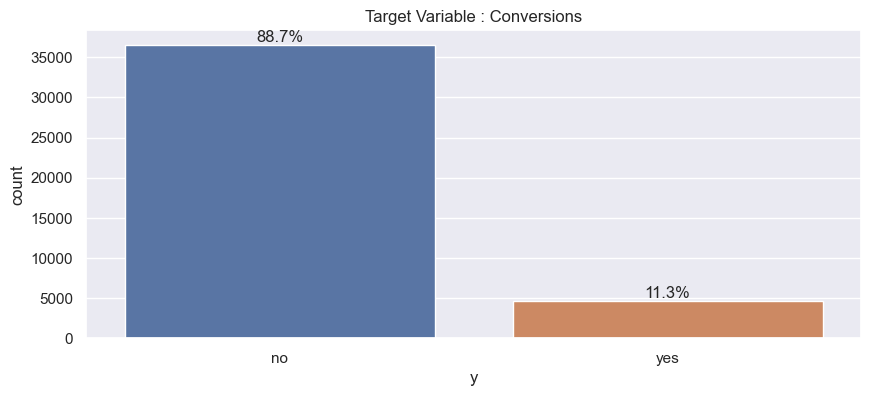

In [20]:
# Distribution of Y
plt.figure(figsize=(10,4))
ax = sns.countplot(data=df_csv, x='y', hue='y')
plt.title('Target Variable : Conversions');
#add % on top of each bar
for pct in ax.patches:
    ax.annotate(f'{round(pct.get_height()/df_csv.shape[0]*100,1)}%',
                (pct.get_x() + pct.get_width() / 2, pct.get_height()),
                ha='center', va='bottom')

## Univariate structure (numeric)

In [11]:
num_cols = ['age', 'duration', 'campaign',
            'pdays', 'previous', 'emp.var.rate',
            'cons.price.idx', 'cons.conf.idx','euribor3m','nr.employed']
df_csv[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


#### Based on above univariate numeric stucture, we will calculate the skewness for each followed by the univariate bar plots

In [17]:
# Calculate skewness for all numerical features
numeric_skewness = df_csv.skew(numeric_only=True)

#Display the skewness values
print("### Skewness for Bank Marketing Numeric Columns ###")
print(numeric_skewness.sort_values(ascending=False))

### Skewness for Bank Marketing Numeric Columns ###
campaign          4.762507
previous          3.832042
duration          3.263141
age               0.784697
cons.conf.idx     0.303180
cons.price.idx   -0.230888
euribor3m        -0.709188
emp.var.rate     -0.724096
nr.employed      -1.044262
pdays            -4.922190
dtype: float64


In [9]:
# fig, axes = plt.subplots(2, 5, figsize=(15, 5))
# for ax, col in zip(axes.ravel(),
#                    ['age', 'duration', 'campaign', 'pdays', 'previous',
#             'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
#             'euribor3m', 'nr.employed']):
#     df_csv[col].plot(kind='hist', bins=30, ax=ax, edgecolor='white')
#     ax.set_title(col)
# fig.tight_layout(); 
# plt.show()

                skew   kurt  nunique  iqr_outliers
age             0.78   0.79     78.0           469
duration        3.26  20.25   1544.0          2963
campaign        4.76  36.98     42.0          2406
pdays          -4.92  22.23     27.0          1515
previous        3.83  20.11      8.0          5625
emp.var.rate   -0.72  -1.06     10.0             0
cons.price.idx -0.23  -0.83     26.0             0
cons.conf.idx   0.30  -0.36     26.0           447
euribor3m      -0.71  -1.41    316.0             0
nr.employed    -1.04  -0.00     11.0             0


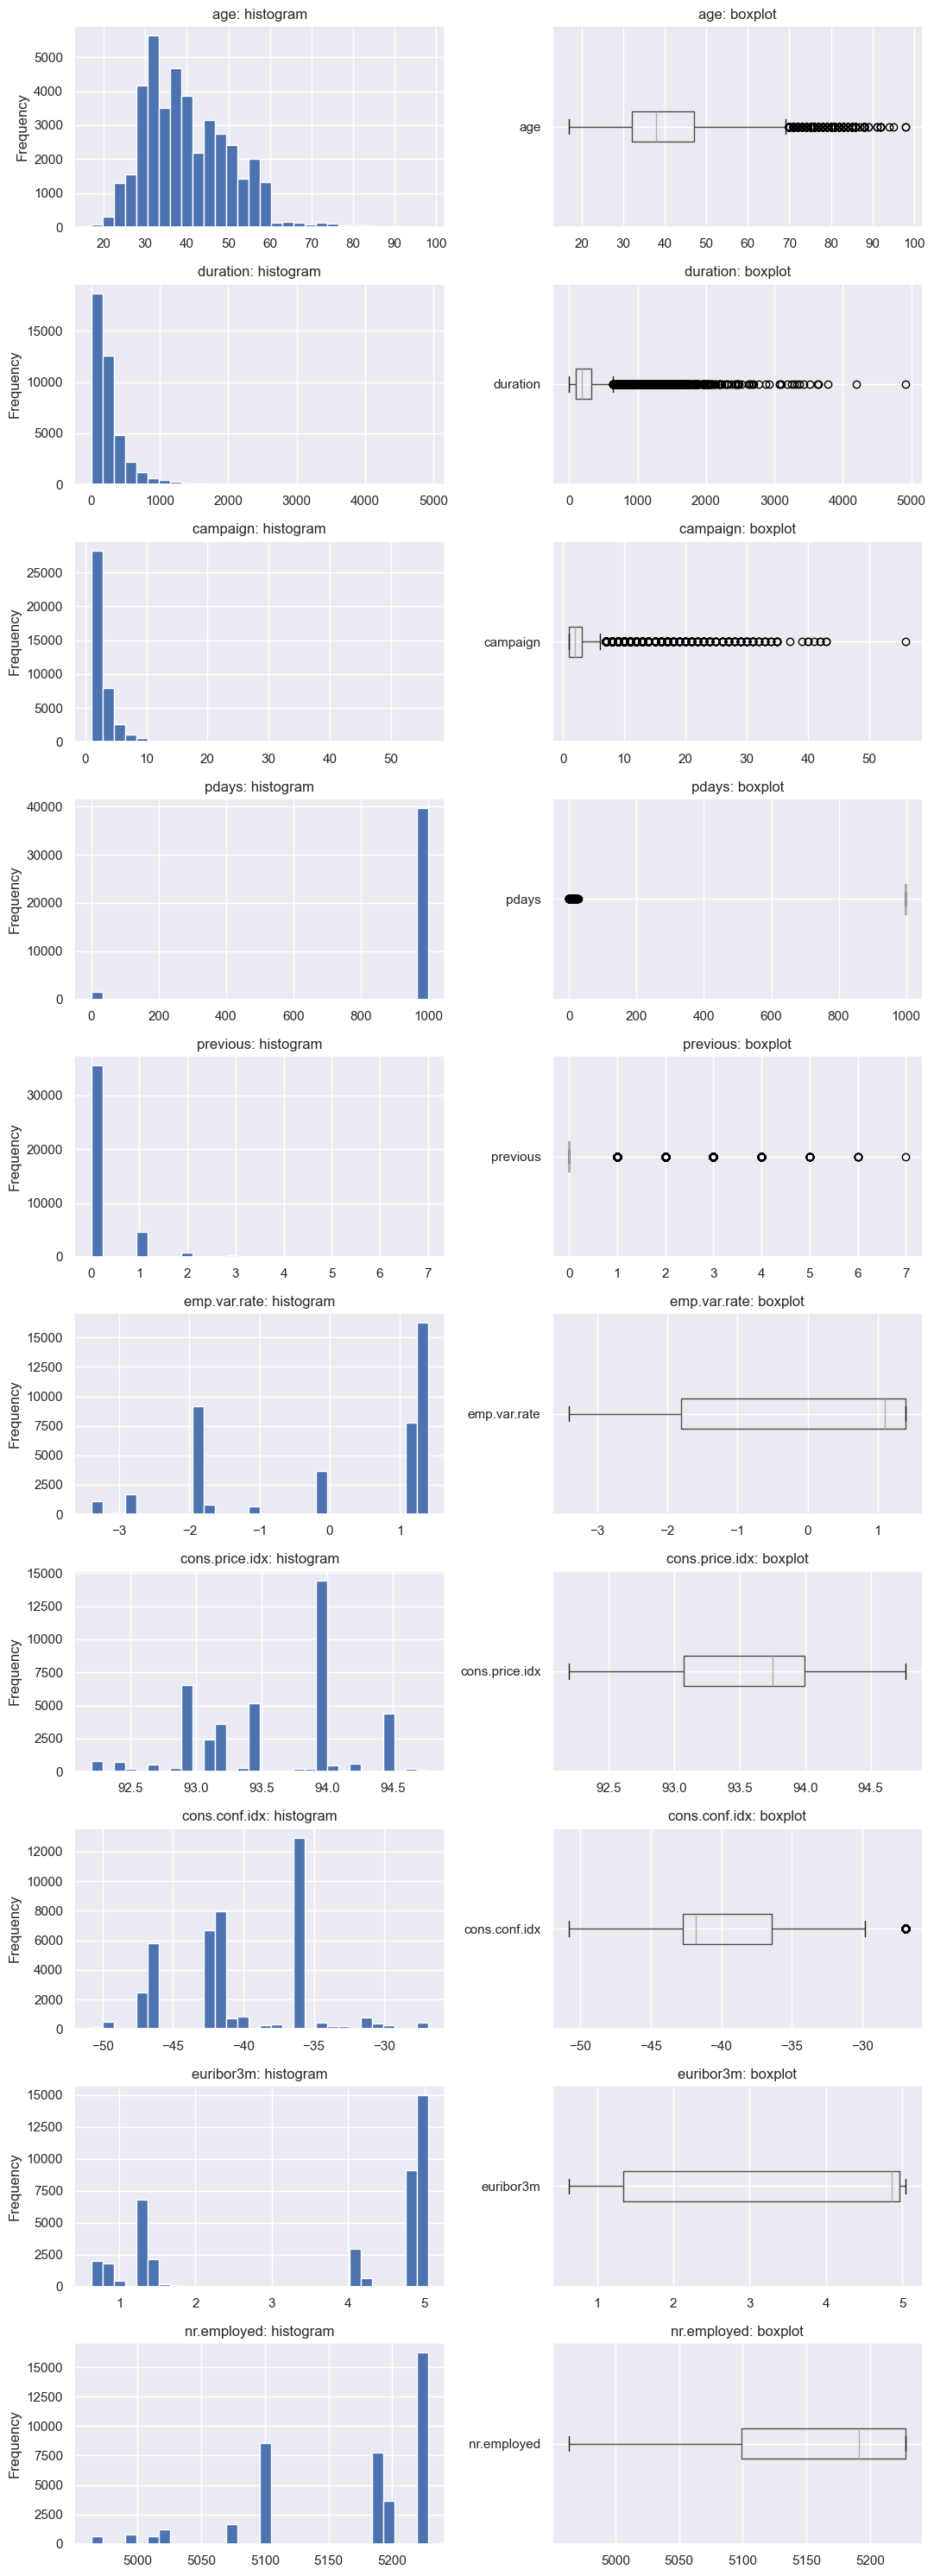

In [16]:

num_cols = ['age', 'duration', 'campaign', 'pdays', 'previous',
            'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
            'euribor3m', 'nr.employed']

summary = df_csv[num_cols].agg(['skew', 'kurt', 'nunique']).T
q1, q3 = df_csv[num_cols].quantile(0.25), df_csv[num_cols].quantile(0.75)
iqr = q3 - q1
summary['iqr_outliers'] = ((df_csv[num_cols] < q1 - 1.5*iqr) |
                           (df_csv[num_cols] > q3 + 1.5*iqr)).sum()
print(summary.round(2))

fig, axes = plt.subplots(len(num_cols), 2, figsize=(11, 3*len(num_cols)))
for i, col in enumerate(num_cols):
    df_csv[col].plot(kind='hist', bins=30, ax=axes[i, 0], edgecolor='white')
    axes[i, 0].set_title(f'{col}: histogram')
    df_csv.boxplot(column=col, ax=axes[i, 1], vert=False)
    axes[i, 1].set_title(f'{col}: boxplot')
fig.tight_layout()
plt.show()

In [36]:
# Categorical Columns
#cat_cols = df_csv.select_dtypes(include='object').columns
#print(cat_cols)
for cat_cols in ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome']:
    print(f"--- {cat_cols}")
    print(df_csv[cat_cols].value_counts(normalize=True).round(3).to_string(), "\n")

--- job
job
admin.           0.253
blue-collar      0.225
technician       0.164
services         0.096
management       0.071
retired          0.042
entrepreneur     0.035
self-employed    0.035
housemaid        0.026
unemployed       0.025
student          0.021
unknown          0.008 

--- marital
marital
married     0.605
single      0.281
divorced    0.112
unknown     0.002 

--- education
education
university.degree      0.295
high.school            0.231
basic.9y               0.147
professional.course    0.127
basic.4y               0.101
basic.6y               0.056
unknown                0.042
illiterate             0.000 

--- default
default
no         0.791
unknown    0.209
yes        0.000 

--- housing
housing
yes        0.524
no         0.452
unknown    0.024 

--- loan
loan
no         0.824
yes        0.152
unknown    0.024 

--- contact
contact
cellular     0.635
telephone    0.365 

--- month
month
may    0.334
jul    0.174
aug    0.150
jun    0.129
nov    0.100
apr 

### Bivariate Plots: Which features move with deault

1. **Age versus Conversion** |
Customers who converted to the campaigns are slightly younger than those who did not.

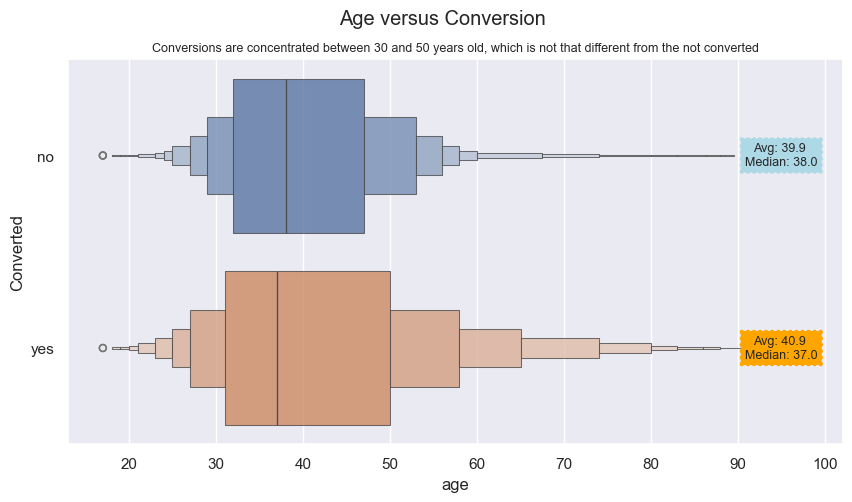

In [20]:
# Age versus Conversion
plt.figure( figsize=(10,5))
ax = sns.boxenplot(data=df_csv, x='age', y='y', hue='y', alpha=0.8)
plt.suptitle('Age versus Conversion')
plt.ylabel('Converted')
plt.title('Conversions are concentrated between 30 and 50 years old, which is not that different from the not converted', size=9)

# Annotation
# Medians and Averages
median_converted = df_csv.query('y == "yes"')['age'].median()
median_not_converted = df_csv.query('y == "no"')['age'].median()
avg_converted = df_csv.query('y == "yes"')['age'].mean()
avg_not_converted = df_csv.query('y == "no"')['age'].mean()
# Annotation - Insert text with Average and Median for each category
plt.text(95, 0, f"Avg: {round(avg_not_converted,1)} \nMedian: {median_not_converted}",
         ha="center", va="center", rotation=0,
         size=9, bbox=dict(boxstyle="roundtooth, pad=0.5", fc="lightblue", ec="r", lw=0))
plt.text(95, 1, f"Avg: {round(avg_converted,1)} \nMedian: {median_converted}",
         ha="center", va="center", rotation=0,
         size=9, bbox=dict(boxstyle="roundtooth, pad=0.5", fc="orange", ec="r", lw=0));

**Job versus Conversions**

C:\Users\anoop\AppData\Local\Temp\ipykernel_20156\4255997562.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=converted,
C:\Users\anoop\AppData\Local\Temp\ipykernel_20156\4255997562.py:7: UserWarning: 
The palette list has fewer values (11) than needed (12) and will cycle, which may produce an uninterpretable plot.
  ax = sns.countplot(data=converted,


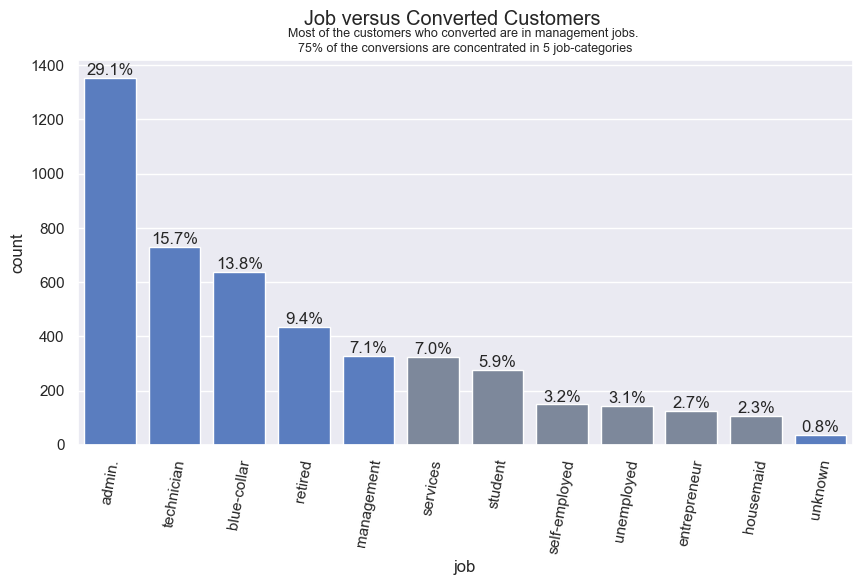

In [30]:
# job versus Conversions == "YES"
converted = df_csv.query('y == "yes"')
plt.figure( figsize=(10,5))
# order of the bars from highest to lowest
order = df_csv.query('y == "yes"')['job'].value_counts().index
# Plot and title
ax = sns.countplot(data=converted,
                   x='job',
                   order=order,
                   palette= 5*["#4978d0"] + 6*["#7886a0"])
plt.suptitle('Job versus Converted Customers')
plt.title('Most of the customers who converted are in management jobs. \n75% of the conversions are concentrated in 5 job-categories', size=9);
# X label rotation
plt.xticks(rotation=80);
#add % on top of each bar
for pct in ax.patches:
    ax.annotate(f'{round(pct.get_height()/converted.shape[0]*100,1)}%',
                (pct.get_x() + pct.get_width() / 2, pct.get_height()),
                ha='center', va='bottom')

## Duplicate Record Analysis

**A full row duplicate check was performed using Pandas duplicated() method. The initial dataset contained 12 duplicate occurrences, meaning 12 rows duplicated previously occurring rows across all columns.**

The duplicate records were inspected using duplicated(keep=False), which displays every occurrence belonging to a duplicate group.

After verifying that the exact duplicates did not represent legitimate separate observations, subsequent duplicate occurrences were removed using drop_duplicates(). The number of rows before and after cleaning was recorded, and the cleaned dataset was checked to confirm that no full-row duplicates remained.

This step reduces the risk of repeated records disproportionately influencing exploratory statistics and model training.

In [18]:
df_clean = df_csv.drop_duplicates(keep="first").reset_index(drop=True)
print(f"Removed {len(df_csv) - len(df_clean)} rows; new shape: {df_clean.shape}")

Removed 12 rows; new shape: (41176, 21)


Lets do an IQR and Skewness summary for the clean data to check if it has any effect on the outliers

In [19]:
summary = df_clean[num_cols].agg(['skew', 'kurt', 'nunique']).T
q1, q3 = df_clean[num_cols].quantile(0.25), df_clean[num_cols].quantile(0.75)
iqr = q3 - q1
summary['iqr_outliers'] = ((df_clean[num_cols] < q1 - 1.5*iqr) |
                           (df_clean[num_cols] > q3 + 1.5*iqr)).sum()
print(summary.round(2))

                skew   kurt  nunique  iqr_outliers
age             0.78   0.79     78.0           468
duration        3.26  20.24   1544.0          2963
campaign        4.76  36.97     42.0          2406
pdays          -4.92  22.22     27.0          1515
previous        3.83  20.10      8.0          5625
emp.var.rate   -0.72  -1.06     10.0             0
cons.price.idx -0.23  -0.83     26.0             0
cons.conf.idx   0.30  -0.36     26.0           446
euribor3m      -0.71  -1.41    316.0             0
nr.employed    -1.04  -0.00     11.0             0


## We split the data into training and test data

In [13]:
# Split in train and test sets
X_train, X_test, y_train, y_test = train_test_split(df_clean.drop('y', axis=1),
                                                    df_clean['y'],
                                                    test_size=0.2,
                                                    stratify=df_clean['y'],
                                                    random_state=42)

# train
df_train = pd.concat([X_train, y_train], axis=1)

# test
df_test = pd.concat([X_test, y_test], axis=1)

#print(df_train.columns.tolist())
#print(df_test.columns.tolist())

## Comparison between boxplot and boxenplot

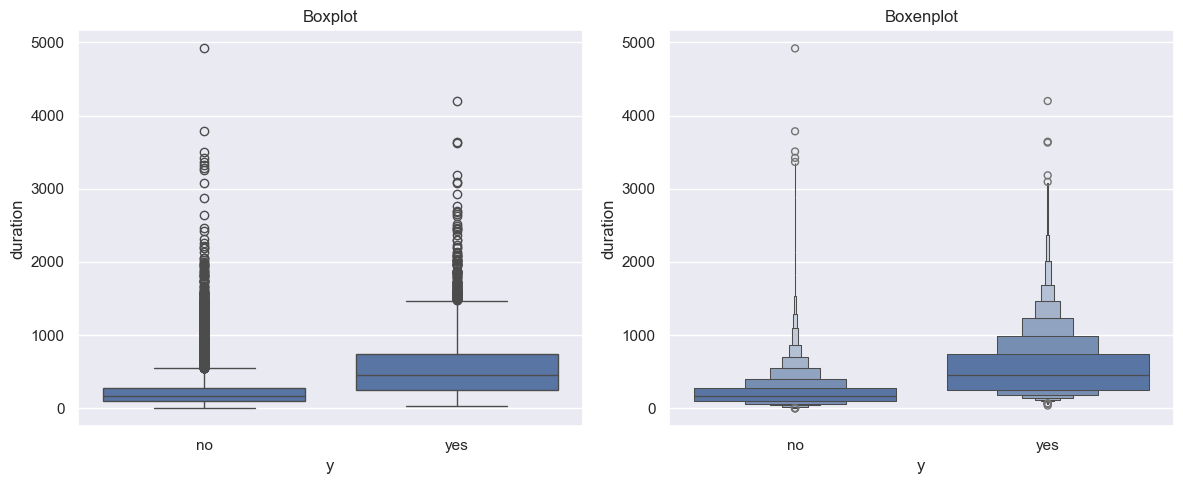

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df_csv, x="y", y="duration", ax=axes[0])
axes[0].set_title("Boxplot")
sns.boxenplot(data=df_csv, x="y", y="duration", ax=axes[1])
axes[1].set_title("Boxenplot")
plt.tight_layout()
plt.show()

# Data Preparation